In [46]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

In [ ]:
project_root = Path.cwd().parent.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import src.mapping_migrations as mm

In [ ]:
data_dir = project_root / "data/"
outputs_dir = project_root / "outputs/"
database_path = data_dir / "all_hiski_records.sqlite3"

FUZZY_SCORE_CUTOFF = 90
MIGRATION_KIND = None

toponyms_with_coordinates = mm.load_toponym_lookup(
    outputs_dir / "json/db_toponyms_with_coordinates_extended.json"
)

## Load tables

In [48]:
emigrated_records, immigrated_records = mm.load_database_migration_tables(database_path)
parish_records = mm.load_parish_records(database_path)

## Resolve toponyms and coordinates

In [49]:
emigrations_with_counterpart = mm.attach_counterpart_toponyms(
    emigrated_records,
    "destination",
    toponyms_with_coordinates,
    FUZZY_SCORE_CUTOFF,
)
immigrations_with_counterpart = mm.attach_counterpart_toponyms(
    immigrated_records,
    "source",
    toponyms_with_coordinates,
    FUZZY_SCORE_CUTOFF
)

parish_coordinates = mm.build_parish_coordinates(
    parish_records, toponyms_with_coordinates
)
parish_names_not_in_dict = parish_coordinates.loc[
    ~parish_coordinates["parish_name"]
    .str.strip()
    .isin(toponyms_with_coordinates),
    "parish_name",
]
print(
    f"{len(parish_names_not_in_dict)} of {len(parish_coordinates)}",
    "parish names are not in the toponym dict",
)

  0%|          | 0/12375 [00:00<?, ?it/s]

  0%|          | 0/14358 [00:00<?, ?it/s]

1 of 522 parish names are not in the toponym dict


In [50]:
emigrations_located = mm.attach_coordinates(
    emigrations_with_counterpart, parish_coordinates
)
immigrations_located = mm.attach_coordinates(
    immigrations_with_counterpart, parish_coordinates
)

plottable_emigrations = mm.drop_records_missing_coordinates(
    emigrations_located
)
plottable_immigrations = mm.drop_records_missing_coordinates(
    immigrations_located
)
print(
    len(plottable_emigrations), "emigration rows and",
    len(plottable_immigrations), "immigration rows can be plotted",
)

135648 emigration rows and 165117 immigration rows can be plotted


In [36]:
migrations = mm.build_migrations(plottable_emigrations, plottable_immigrations)

## Static map

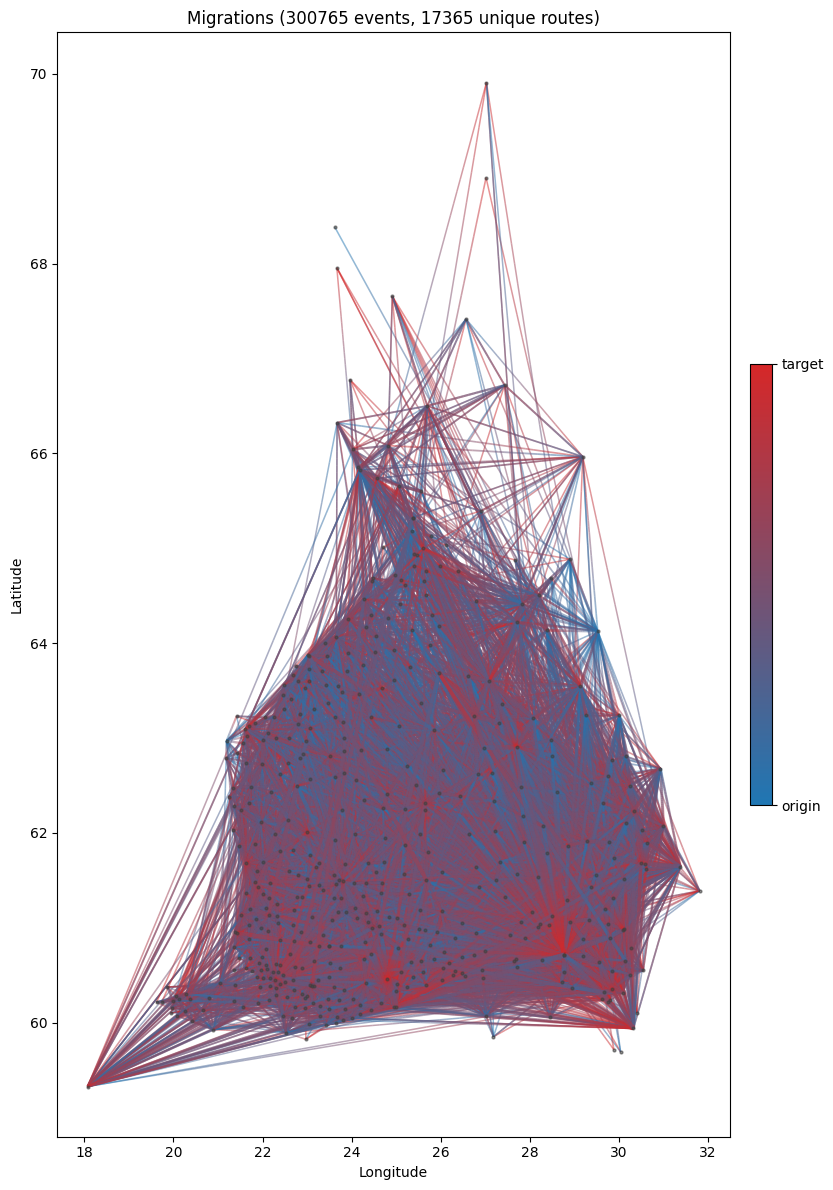

In [37]:
figure, map_axes, unique_routes = mm.draw_static_migration_map(migrations)
plt.show()

## Interactive map

In [45]:
plot_events = mm.prepare_plot_events(migrations, MIGRATION_KIND, year_bins=None)
yearly_routes = mm.build_yearly_routes(plot_events)
years = sorted(yearly_routes[mm.YEAR_BIN_COLUMN].unique())
print(f"{len(yearly_routes)} year-routes over {len(years)} years ({years[0]}-{years[-1]})")

88153 year-routes over 188 years (1722-1909)


In [ ]:
migration_figure = mm.build_migration_figure(
    yearly_routes,
    MIGRATION_KIND,
    source_description="Hiski database",
)
migration_figure.show()

In [23]:
Path("migrations_db.html").write_text(migration_figure.to_html())

73941318

## Metrics

In [38]:
display("emigrated (destination)", mm.summarize_toponym_coverage(emigrations_located))
display("immigrated (source)", mm.summarize_toponym_coverage(immigrations_located))

'emigrated (destination)'

,count
rows,182137
empty place name,8016
exact match,134958
fuzzy match,6186
no match,32977
"matched, but no coordinates",3864
"matched, with coordinates",137280


'immigrated (source)'

,count
rows,212902
empty place name,8120
exact match,164700
fuzzy match,7080
no match,33002
"matched, but no coordinates",4065
"matched, with coordinates",167715


In [39]:
migrations["distance"] = mm.compute_distances_in_metres(migrations)
print(
    "mean:", round(migrations["distance"].mean() / 1000), "km\n"
    "median:", round(migrations["distance"].median() / 1000), "km\n"
    "mode:", round(migrations["distance"].mode()[0] / 1000), "km"
)

mean: 76 km
median: 34 km
mode: 19 km


In [40]:
unique_migrations = (
    migrations[["kind", "origin_name", "target_name", "distance"]]
    .drop_duplicates()
    .sort_values(by="distance", ascending=False)
)
unique_migrations

,kind,origin_name,target_name,distance
289153,immigration,Utsjoki,Viipuri,1.028468e+06
209004,immigration,Tukholma,Kuusamo,9.312728e+05
64048,emigration,Kuusamo,Tukholma,9.312728e+05
102537,emigration,Sortavala,Inari,8.209965e+05
52285,emigration,Karunki,Tukholma,8.072779e+05
...,...,...,...,...
276077,immigration,Suomenlinna,Suomenlinna,0.000000e+00
138525,immigration,Ahlainen,Ahlainen,0.000000e+00
191928,immigration,Karunki,Karunki,0.000000e+00
185930,immigration,Jääski,Jääski,0.000000e+00


In [41]:
print(migrations["origin_name"].value_counts().head(10).to_string())

origin_name
Viipuri             11390
Sortavala            6152
Akaa                 5714
Helsinki             4503
Helsingin pitäjä     4243
Vihti                4165
Iisalmi              4040
Hämeenlinna          4010
Janakkala            3947
Tohmajärvi           3884


In [42]:
print(migrations["target_name"].value_counts().head(10).to_string())

target_name
Viipuri        20404
Nurmijärvi     11558
Sortavala       7842
Helsinki        6245
Hämeenlinna     5003
Turku           4863
Kuopio          4714
Tampere         4369
Kurkijoki       4284
Tohmajärvi      4101


In [43]:
mm.count_fuzzy_matches(emigrations_located).head(25)

counterpart_raw_name  counterpart_matched_key  counterpart_normalized_name  counterpart_match_score
Kyrckslätt            Kyrkslätt                Kirkkonummi                  94.736842                  153
Wehkalahti            Vehkalahti               Vehkalahti                   90.000000                  140
Karku                 Karkku                   Karkku                       90.909091                  129
Nurmjärvi             Nurmijärvi               Nurmijärvi                   94.736842                  126
Willmanstrand         Villmanstrand            Lappeenranta                 92.307692                  115
Bborg                 B:borg                   Pori                         90.909091                  107
St Carin              St. Carin                Kaarina                      94.117647                   97
Thomajärvi            Tohmajärvi               Tohmajärvi                   90.000000                   77
Jäskis                Jääskis               

In [44]:
for located_records, place_label in [
    (emigrations_located, "destination"),
    (immigrations_located, "source"),
]:
    unmatched_name_counts = mm.count_unmatched_names(located_records)
    print(f"\nTop unmatched {place_label} values:")
    print(unmatched_name_counts.head(10).to_string())
    print("total unmatched:", unmatched_name_counts.sum())


Top unmatched destination values:
counterpart_raw_name
kaup.      694
K:joki     461
S:mäki     391
Kaup.      381
-          311
Gardet     217
Mod:k:n    212
Rautio     209
K:slätt    186
Pielis     177
total unmatched: 32977

Top unmatched source values:
counterpart_raw_name
kaup.          791
K:joki         323
-              308
Kaup.          254
Rautio         225
Ilmola         213
Gammelby       208
Pielis         148
Walkeasaari    148
T:kyro         127
total unmatched: 33002
